In [1]:
import matplotlib.pyplot as plt
import pandas as pd 

df = pd.read_csv("/kaggle/input/datasets/gregorut/videogamesales/vgsales.csv")

print(df.head())
print(df.shape)
print(df.columns.tolist())
print(df.info())
print(df.isnull().sum())

   Rank                      Name Platform    Year         Genre Publisher  \
0     1                Wii Sports      Wii  2006.0        Sports  Nintendo   
1     2         Super Mario Bros.      NES  1985.0      Platform  Nintendo   
2     3            Mario Kart Wii      Wii  2008.0        Racing  Nintendo   
3     4         Wii Sports Resort      Wii  2009.0        Sports  Nintendo   
4     5  Pokemon Red/Pokemon Blue       GB  1996.0  Role-Playing  Nintendo   

   NA_Sales  EU_Sales  JP_Sales  Other_Sales  Global_Sales  
0     41.49     29.02      3.77         8.46         82.74  
1     29.08      3.58      6.81         0.77         40.24  
2     15.85     12.88      3.79         3.31         35.82  
3     15.75     11.01      3.28         2.96         33.00  
4     11.27      8.89     10.22         1.00         31.37  
(16598, 11)
['Rank', 'Name', 'Platform', 'Year', 'Genre', 'Publisher', 'NA_Sales', 'EU_Sales', 'JP_Sales', 'Other_Sales', 'Global_Sales']
<class 'pandas.core.frame.D


# Video Game Sales Analysis

## Project Overview

This project explores global video game sales data to identify trends and patterns across gaming platforms, genres, publishers, and geographic regions.

Using Python, Pandas, and Matplotlib, I performed data cleaning, exploratory data analysis (EDA), statistical comparisons, and data visualization to uncover meaningful insights about video game sales performance.

## Objectives

- Identify the highest-selling video game genres and platforms.
- Compare publisher performance using total and average sales.
- Analyze sales trends over time.
- Explore regional differences in video game sales.
- Identify top-selling games and sales concentration patterns.

## Tools & Technologies

- Python
- Pandas
- Matplotlib
- Jupyter Notebook

## Dataset

The dataset contains 16,598 video game records and 11 columns, including game titles, platforms, release years, genres, publishers, regional sales, and global sales.

Sales values are measured in millions of units.


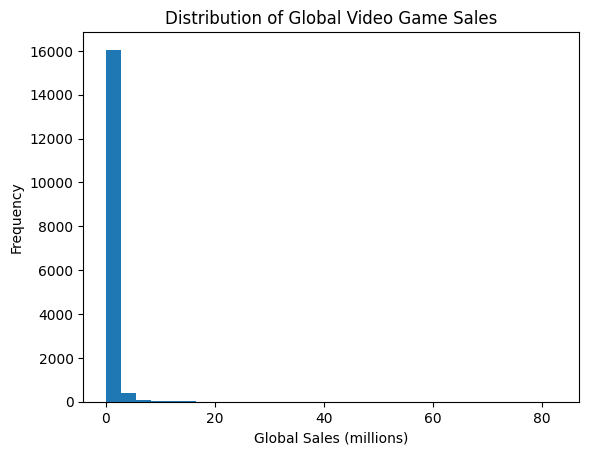

In [2]:
df["Global_Sales"].plot(
    kind="hist",
    bins=30
)

plt.title("Distribution of Global Video Game Sales")
plt.xlabel("Global Sales (millions)")
plt.ylabel("Frequency")

plt.show()

Genre
Platform        0.938341
Shooter         0.791885
Role-Playing    0.623233
Racing          0.586101
Sports          0.567319
Fighting        0.529375
Action          0.528100
Misc            0.465762
Simulation      0.452364
Puzzle          0.420876
Strategy        0.257151
Adventure       0.185879
Name: Global_Sales, dtype: float64


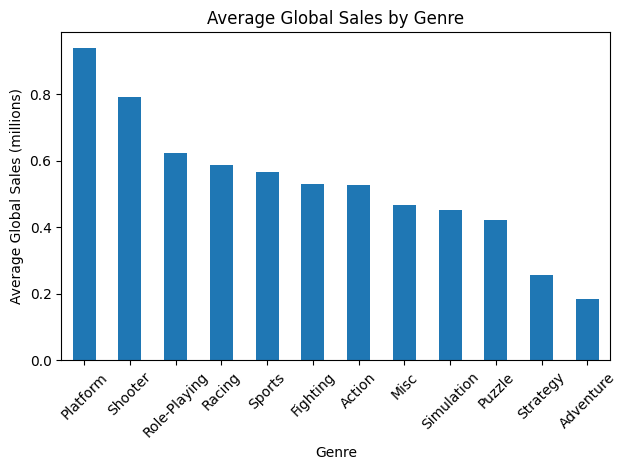

In [3]:
genre_sales = df.groupby("Genre")["Global_Sales"].mean()

genre_sales = genre_sales.sort_values(
    ascending=False
)

print(genre_sales)

genre_sales.plot(
    kind="bar"
)

plt.title("Average Global Sales by Genre")
plt.xlabel("Genre")
plt.ylabel("Average Global Sales (millions)")

plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

Platform
PS2     1255.64
X360     979.96
PS3      957.84
Wii      926.71
DS       822.49
PS       730.66
GBA      318.50
PSP      296.28
PS4      278.10
PC       258.82
Name: Global_Sales, dtype: float64


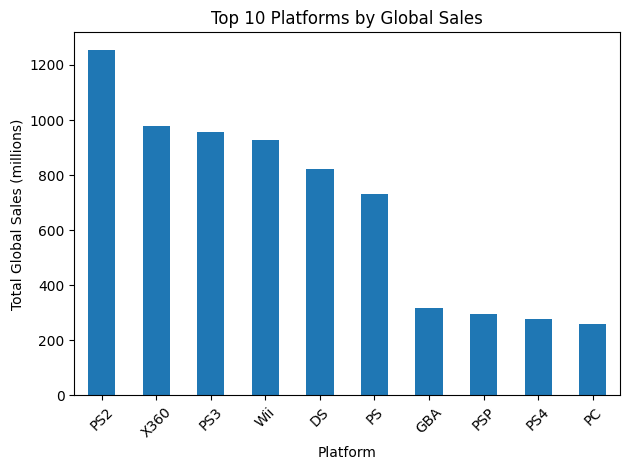

In [4]:
platform_sales = df.groupby("Platform")["Global_Sales"].sum()

platform_sales = platform_sales.sort_values(
    ascending=False
).head(10)

print(platform_sales)

platform_sales.plot(
    kind="bar"
)

plt.title("Top 10 Platforms by Global Sales")
plt.xlabel("Platform")
plt.ylabel("Total Global Sales (millions)")

plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

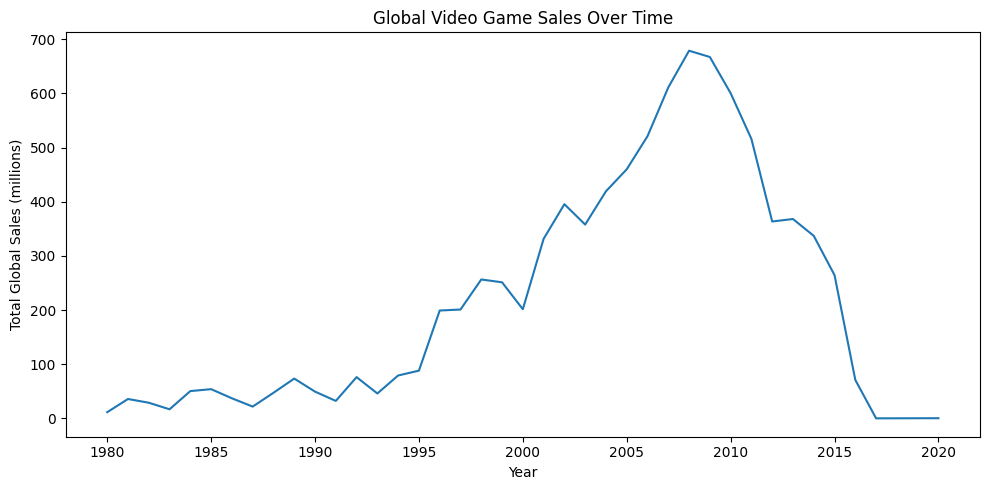

In [5]:
yearly_sales = df.groupby("Year")["Global_Sales"].sum()

yearly_sales.plot(
    kind="line",
    figsize=(10, 5)
)

plt.title("Global Video Game Sales Over Time")
plt.xlabel("Year")
plt.ylabel("Total Global Sales (millions)")

plt.tight_layout()
plt.show()

In [6]:
top_sales = df.sort_values(
    by="Global_Sales",
    ascending=False
).head(10)

print(
    top_sales[
        ["Name", "Platform", "Genre", "Publisher", "Global_Sales"]
    ]
)

                        Name Platform         Genre Publisher  Global_Sales
0                 Wii Sports      Wii        Sports  Nintendo         82.74
1          Super Mario Bros.      NES      Platform  Nintendo         40.24
2             Mario Kart Wii      Wii        Racing  Nintendo         35.82
3          Wii Sports Resort      Wii        Sports  Nintendo         33.00
4   Pokemon Red/Pokemon Blue       GB  Role-Playing  Nintendo         31.37
5                     Tetris       GB        Puzzle  Nintendo         30.26
6      New Super Mario Bros.       DS      Platform  Nintendo         30.01
7                   Wii Play      Wii          Misc  Nintendo         29.02
8  New Super Mario Bros. Wii      Wii      Platform  Nintendo         28.62
9                  Duck Hunt      NES       Shooter  Nintendo         28.31


NA_Sales       4392.95
EU_Sales       2434.13
JP_Sales       1291.02
Other_Sales     797.75
dtype: float64


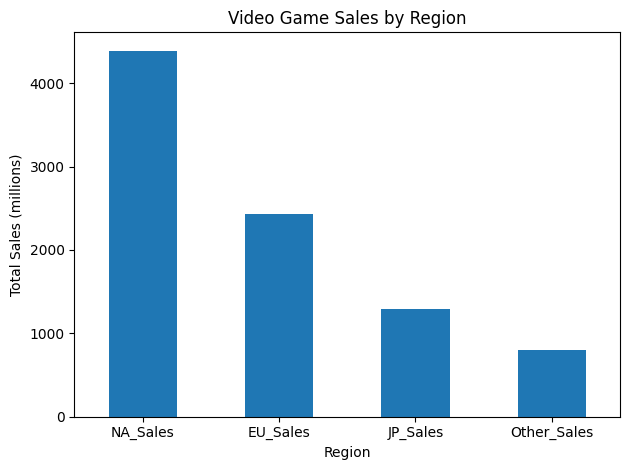

In [7]:
regional_sales = df[
    ["NA_Sales", "EU_Sales", "JP_Sales", "Other_Sales"]
].sum()

print(regional_sales)

regional_sales.plot(
    kind="bar"
)

plt.title("Video Game Sales by Region")
plt.xlabel("Region")
plt.ylabel("Total Sales (millions)")

plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

In [8]:
Publisher = df.groupby("Publisher")["Global_Sales"].sum().sort_values(ascending=False)

In [9]:
print("TOP GENRE:")
print(genre_sales.head(1))

print("\nTOP PLATFORM:")
print(platform_sales.head(1))

print("\nTOP PUBLISHER:")
print(Publisher.head(1))

print("\nTOP GAME:")
print(top_sales.iloc[0][["Name", "Global_Sales"]])

TOP GENRE:
Genre
Platform    0.938341
Name: Global_Sales, dtype: float64

TOP PLATFORM:
Platform
PS2    1255.64
Name: Global_Sales, dtype: float64

TOP PUBLISHER:
Publisher
Nintendo    1786.56
Name: Global_Sales, dtype: float64

TOP GAME:
Name            Wii Sports
Global_Sales         82.74
Name: 0, dtype: object


In [10]:
print("Dataset Shape:", df.shape)

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:")
print(df.duplicated().sum())

print("\nData Types:")
print(df.dtypes)

print("\nUnique Values:")
print("Platforms:", df["Platform"].nunique())
print("Genres:", df["Genre"].nunique())
print("Publishers:", df["Publisher"].nunique())

Dataset Shape: (16598, 11)

Missing Values:
Rank              0
Name              0
Platform          0
Year            271
Genre             0
Publisher        58
NA_Sales          0
EU_Sales          0
JP_Sales          0
Other_Sales       0
Global_Sales      0
dtype: int64

Duplicate Rows:
0

Data Types:
Rank              int64
Name             object
Platform         object
Year            float64
Genre            object
Publisher        object
NA_Sales        float64
EU_Sales        float64
JP_Sales        float64
Other_Sales     float64
Global_Sales    float64
dtype: object

Unique Values:
Platforms: 31
Genres: 12
Publishers: 578


In [11]:
df_clean = df.copy()

# Replace missing publishers
df_clean["Publisher"] = df_clean["Publisher"].fillna("Unknown")

# Convert Year to nullable integer
df_clean["Year"] = df_clean["Year"].astype("Int64")

# Verify cleaning
print("Original Dataset:", df.shape)
print("Cleaned Dataset:", df_clean.shape)

print("\nMissing Values After Cleaning:")
print(df_clean.isnull().sum())

print("\nYear Data Type:", df_clean["Year"].dtype)

Original Dataset: (16598, 11)
Cleaned Dataset: (16598, 11)

Missing Values After Cleaning:
Rank              0
Name              0
Platform          0
Year            271
Genre             0
Publisher         0
NA_Sales          0
EU_Sales          0
JP_Sales          0
Other_Sales       0
Global_Sales      0
dtype: int64

Year Data Type: Int64


In [12]:
sales_columns = [
    "NA_Sales",
    "EU_Sales",
    "JP_Sales",
    "Other_Sales"
]

# Compare regional sales with global sales
df_clean["Calculated_Global_Sales"] = df_clean[sales_columns].sum(axis=1)

df_clean["Sales_Difference"] = (
    df_clean["Global_Sales"] - df_clean["Calculated_Global_Sales"]
)

print("Negative Sales Values:")
print((df_clean[sales_columns + ["Global_Sales"]] < 0).sum())

print("\nSales Differences:")
print(df_clean["Sales_Difference"].abs().describe())

print("\nLargest Sales Difference:")
print(df_clean["Sales_Difference"].abs().max())

Negative Sales Values:
NA_Sales        0
EU_Sales        0
JP_Sales        0
Other_Sales     0
Global_Sales    0
dtype: int64

Sales Differences:
count    16598.000000
mean         0.002724
std          0.004466
min          0.000000
25%          0.000000
50%          0.000000
75%          0.010000
max          0.020000
Name: Sales_Difference, dtype: float64

Largest Sales Difference:
0.020000000000000462


In [13]:
genre_sales = (
    df_clean.groupby("Genre")["Global_Sales"]
    .sum()
    .sort_values(ascending=False)
)

print(genre_sales)

Genre
Action          1751.18
Sports          1330.93
Shooter         1037.37
Role-Playing     927.37
Platform         831.37
Misc             809.96
Racing           732.04
Fighting         448.91
Simulation       392.20
Puzzle           244.95
Adventure        239.04
Strategy         175.12
Name: Global_Sales, dtype: float64


In [14]:
genre_avg_sales = (
    df_clean.groupby("Genre")["Global_Sales"]
    .mean()
    .sort_values(ascending=False)
)

print(genre_avg_sales.round(2))


Genre
Platform        0.94
Shooter         0.79
Role-Playing    0.62
Racing          0.59
Sports          0.57
Fighting        0.53
Action          0.53
Misc            0.47
Simulation      0.45
Puzzle          0.42
Strategy        0.26
Adventure       0.19
Name: Global_Sales, dtype: float64


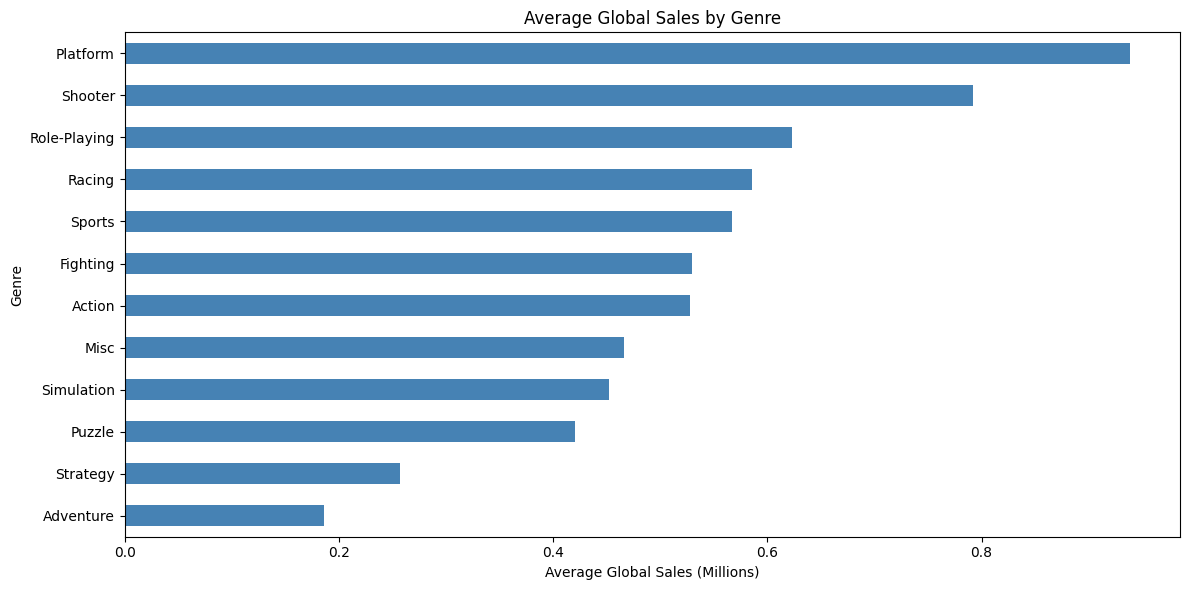

In [15]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))

genre_avg_sales.sort_values().plot(
    kind="barh",
    color="steelblue"
)

plt.title("Average Global Sales by Genre")
plt.xlabel("Average Global Sales (Millions)")
plt.ylabel("Genre")
plt.tight_layout()
plt.show()


In [16]:
genre_comparison = (
    df_clean.groupby("Genre")["Global_Sales"]
    .agg(["count", "mean", "median", "sum"])
    .sort_values("mean", ascending=False)
)

genre_comparison.columns = [
    "Game_Count",
    "Average_Sales",
    "Median_Sales",
    "Total_Sales"
]

print(genre_comparison.round(2))

              Game_Count  Average_Sales  Median_Sales  Total_Sales
Genre                                                             
Platform             886           0.94          0.28       831.37
Shooter             1310           0.79          0.23      1037.37
Role-Playing        1488           0.62          0.18       927.37
Racing              1249           0.59          0.19       732.04
Sports              2346           0.57          0.22      1330.93
Fighting             848           0.53          0.21       448.91
Action              3316           0.53          0.19      1751.18
Misc                1739           0.47          0.16       809.96
Simulation           867           0.45          0.16       392.20
Puzzle               582           0.42          0.11       244.95
Strategy             681           0.26          0.09       175.12
Adventure           1286           0.19          0.06       239.04


### Average vs. Median Sales Analysis

The analysis shows that Platform and Shooter have the highest average global sales per game. However, their median sales are considerably lower than their averages.

This suggests that a smaller number of highly successful games may influence average sales. Action has the highest total sales and game count, making it the largest genre by overall sales volume.

In [17]:
regional_sales = df_clean[
    ["NA_Sales", "EU_Sales", "JP_Sales", "Other_Sales"]
].sum()

regional_percentage = (
    regional_sales / regional_sales.sum()
) * 100

region_analysis = pd.DataFrame({
    "Total_Sales": regional_sales,
    "Sales_Percentage": regional_percentage
})

region_analysis = region_analysis.sort_values(
    "Total_Sales",
    ascending=False
)

print(region_analysis.round(2))

             Total_Sales  Sales_Percentage
NA_Sales         4392.95             49.27
EU_Sales         2434.13             27.30
JP_Sales         1291.02             14.48
Other_Sales       797.75              8.95


In [18]:
yearly_sales = (
    df_clean.dropna(subset=["Year"])
    .groupby("Year")["Global_Sales"]
    .sum()
    .sort_index()
)

print(yearly_sales)

Year
1980     11.38
1981     35.77
1982     28.86
1983     16.79
1984     50.36
1985     53.94
1986     37.07
1987     21.74
1988     47.22
1989     73.45
1990     49.39
1991     32.23
1992     76.16
1993     45.98
1994     79.17
1995     88.11
1996    199.15
1997    200.98
1998    256.47
1999    251.27
2000    201.56
2001    331.47
2002    395.52
2003    357.85
2004    419.31
2005    459.94
2006    521.04
2007    611.13
2008    678.90
2009    667.30
2010    600.45
2011    515.99
2012    363.54
2013    368.11
2014    337.05
2015    264.44
2016     70.93
2017      0.05
2020      0.29
Name: Global_Sales, dtype: float64


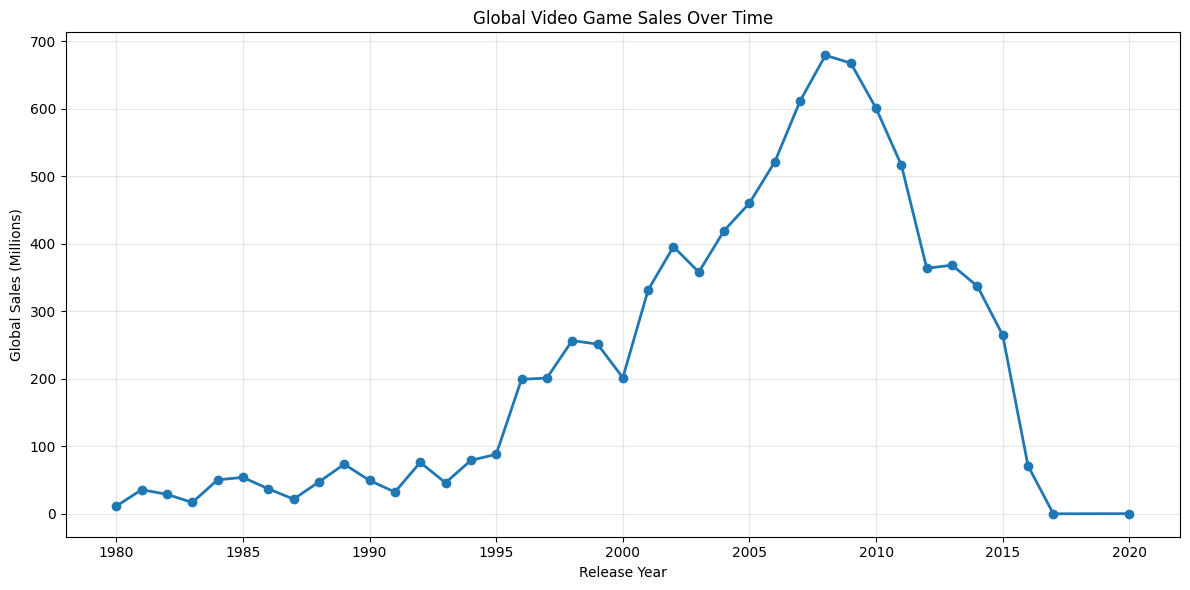

In [19]:
plt.figure(figsize=(12, 6))

plt.plot(
    yearly_sales.index,
    yearly_sales.values,
    marker="o",
    linewidth=2
)

plt.title("Global Video Game Sales Over Time")
plt.xlabel("Release Year")
plt.ylabel("Global Sales (Millions)")

plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [20]:
platform_sales = (
    df_clean.groupby("Platform")["Global_Sales"]
    .sum()
    .sort_values(ascending=False)
)

print(platform_sales.head(10))

Platform
PS2     1255.64
X360     979.96
PS3      957.84
Wii      926.71
DS       822.49
PS       730.66
GBA      318.50
PSP      296.28
PS4      278.10
PC       258.82
Name: Global_Sales, dtype: float64


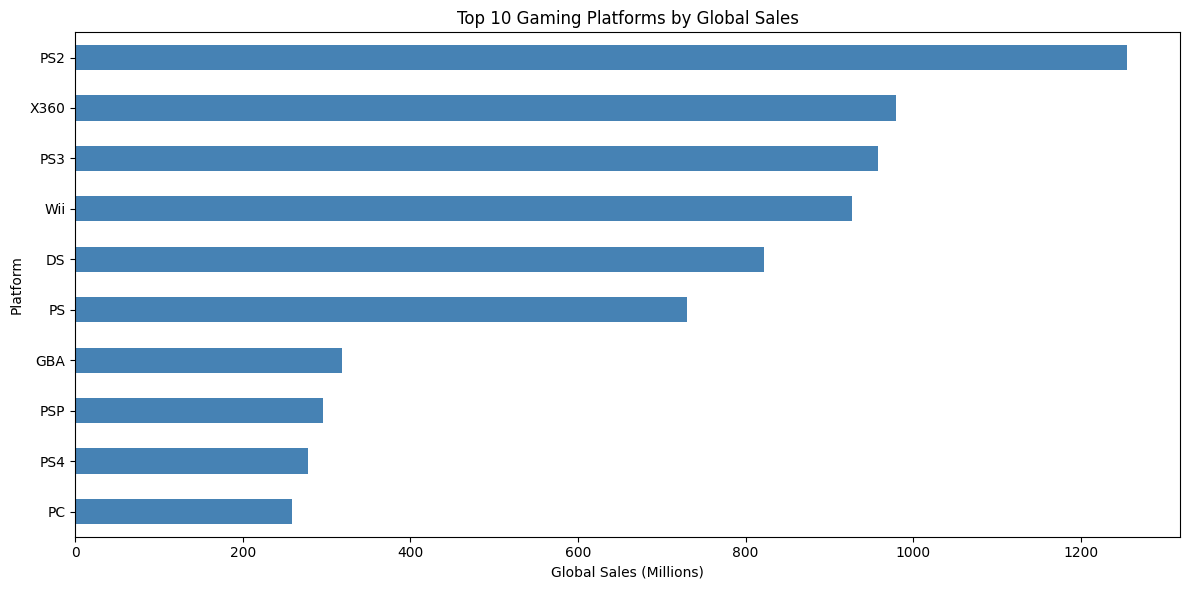

In [21]:
top_platforms = platform_sales.head(10)

plt.figure(figsize=(12, 6))

top_platforms.sort_values().plot(
    kind="barh",
    color="steelblue"
)

plt.title("Top 10 Gaming Platforms by Global Sales")
plt.xlabel("Global Sales (Millions)")
plt.ylabel("Platform")

plt.tight_layout()
plt.show()

Top Gaming Platforms Analysis

The PlayStation 2 generated the highest total global sales, followed by the Xbox 360 and PlayStation 3. Nintendo's Wii and DS also ranked among the top five platforms.

These results show that several major console platforms generated substantial sales during their respective generations.

In [22]:
publisher_sales = (
    df_clean.groupby("Publisher")["Global_Sales"]
    .sum()
    .sort_values(ascending=False)
)

print(publisher_sales.head(10).round(2))

Publisher
Nintendo                        1786.56
Electronic Arts                 1110.32
Activision                       727.46
Sony Computer Entertainment      607.50
Ubisoft                          474.72
Take-Two Interactive             399.54
THQ                              340.77
Konami Digital Entertainment     283.64
Sega                             272.99
Namco Bandai Games               254.09
Name: Global_Sales, dtype: float64


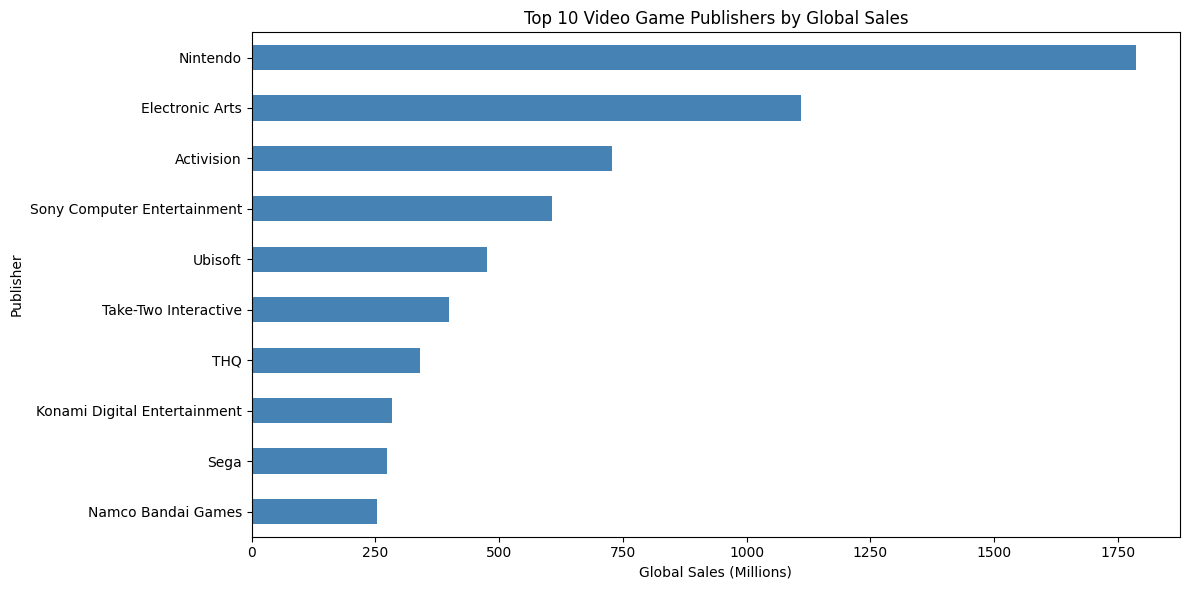

In [23]:
top_publishers = publisher_sales.head(10)

plt.figure(figsize=(12, 6))

top_publishers.sort_values().plot(
    kind="barh",
    color="steelblue"
)

plt.title("Top 10 Video Game Publishers by Global Sales")
plt.xlabel("Global Sales (Millions)")
plt.ylabel("Publisher")

plt.tight_layout()
plt.show()

In [24]:
publisher_comparison = (
    df_clean.groupby("Publisher")["Global_Sales"]
    .agg(["count", "mean", "sum"])
    .sort_values("sum", ascending=False)
    .head(10)
)

publisher_comparison.columns = [
    "Game_Count",
    "Average_Sales",
    "Total_Sales"
]

print(publisher_comparison.round(2))

                              Game_Count  Average_Sales  Total_Sales
Publisher                                                           
Nintendo                             703           2.54      1786.56
Electronic Arts                     1351           0.82      1110.32
Activision                           975           0.75       727.46
Sony Computer Entertainment          683           0.89       607.50
Ubisoft                              921           0.52       474.72
Take-Two Interactive                 413           0.97       399.54
THQ                                  715           0.48       340.77
Konami Digital Entertainment         832           0.34       283.64
Sega                                 639           0.43       272.99
Namco Bandai Games                   932           0.27       254.09


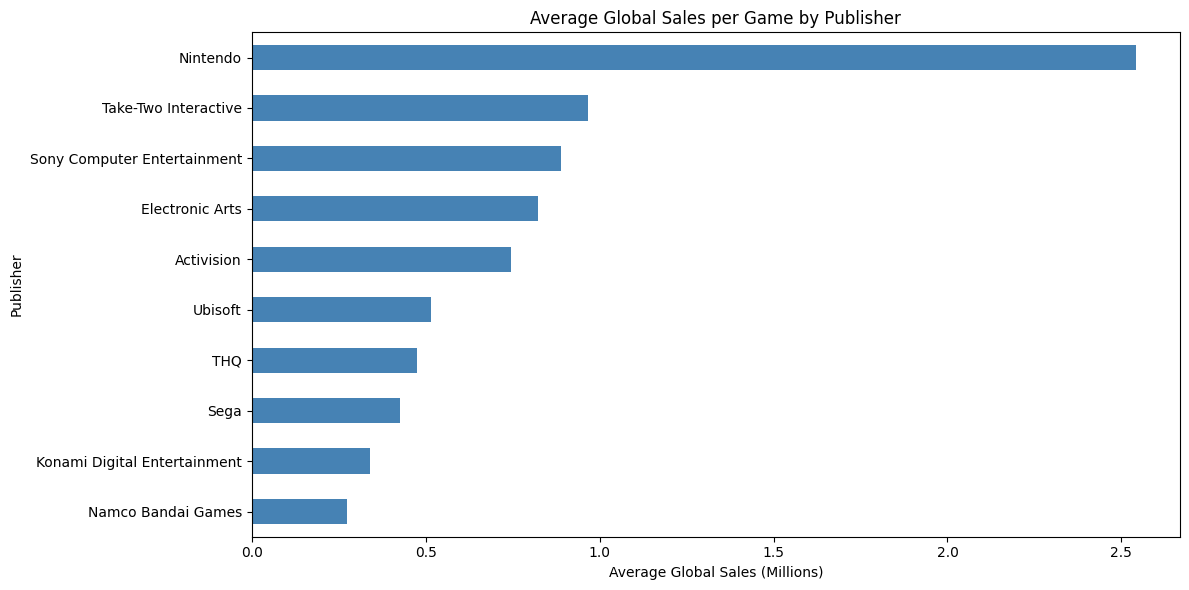

In [25]:
plt.figure(figsize=(12, 6))

publisher_comparison["Average_Sales"].sort_values().plot(
    kind="barh",
    color="steelblue"
)

plt.title("Average Global Sales per Game by Publisher")
plt.xlabel("Average Global Sales (Millions)")
plt.ylabel("Publisher")

plt.tight_layout()
plt.show()

In [26]:
genre_region_sales = (
    df_clean.groupby("Genre")[
        ["NA_Sales", "EU_Sales", "JP_Sales", "Other_Sales"]
    ]
    .sum()
)

print(genre_region_sales.round(2))

              NA_Sales  EU_Sales  JP_Sales  Other_Sales
Genre                                                  
Action          877.83    525.00    159.95       187.38
Adventure       105.80     64.13     52.07        16.81
Fighting        223.59    101.32     87.35        36.68
Misc            410.24    215.98    107.76        75.32
Platform        447.05    201.63    130.77        51.59
Puzzle          123.78     50.78     57.31        12.55
Racing          359.42    238.39     56.69        77.27
Role-Playing    327.28    188.06    352.31        59.61
Shooter         582.60    313.27     38.28       102.69
Simulation      183.31    113.38     63.70        31.52
Sports          683.35    376.85    135.37       134.97
Strategy         68.70     45.34     49.46        11.36


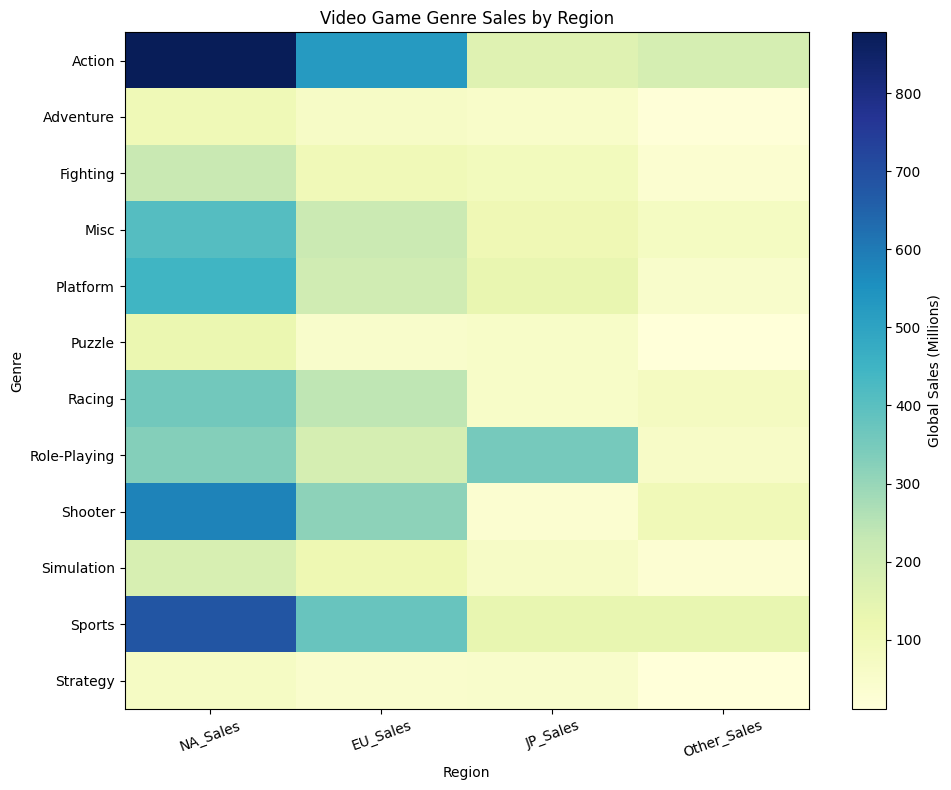

In [27]:
plt.figure(figsize=(10, 8))

plt.imshow(genre_region_sales, aspect="auto", cmap="YlGnBu")

plt.colorbar(label="Global Sales (Millions)")

plt.xticks(
    range(len(genre_region_sales.columns)),
    genre_region_sales.columns,
    rotation=20
)

plt.yticks(
    range(len(genre_region_sales.index)),
    genre_region_sales.index
)

plt.title("Video Game Genre Sales by Region")
plt.xlabel("Region")
plt.ylabel("Genre")

plt.tight_layout()
plt.show()

Regional Genre Preferences

The analysis reveals differences in video game genre preferences across regions. Action games lead in Europe and Other regions, while Sports games generate the highest sales in North America.

Japan shows a different pattern, with Role-Playing games leading all genres in regional sales. This suggests that regional markets have distinct genre preferences.

In [28]:
top_5_platforms = platform_sales.head(5).index

platform_region_sales = (
    df_clean[df_clean["Platform"].isin(top_5_platforms)]
    .groupby("Platform")[
        ["NA_Sales", "EU_Sales", "JP_Sales", "Other_Sales"]
    ]
    .sum()
)

print(platform_region_sales.round(2))

          NA_Sales  EU_Sales  JP_Sales  Other_Sales
Platform                                           
DS          390.71    194.65    175.57        60.53
PS2         583.84    339.29    139.20       193.44
PS3         392.26    343.71     79.99       141.93
Wii         507.71    268.38     69.35        80.61
X360        601.05    280.58     12.43        85.54


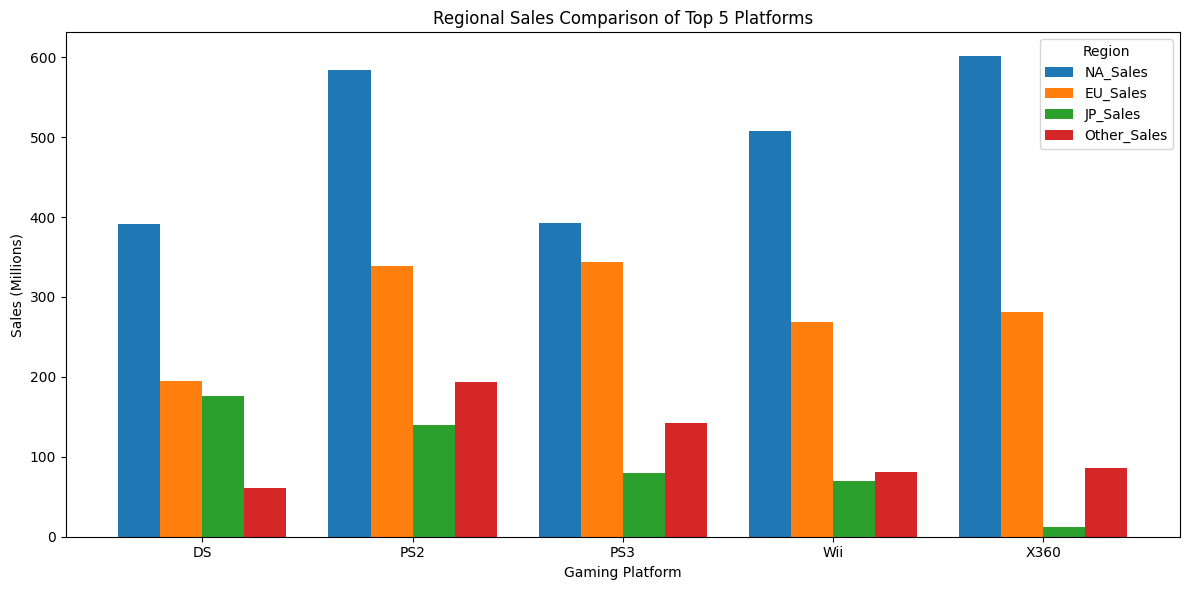

In [29]:
platform_region_sales.plot(
    kind="bar",
    figsize=(12, 6),
    width=0.8
)

plt.title("Regional Sales Comparison of Top 5 Platforms")
plt.xlabel("Gaming Platform")
plt.ylabel("Sales (Millions)")
plt.xticks(rotation=0)
plt.legend(title="Region")
plt.tight_layout()
plt.show()

Regional Platform Performance

The regional comparison shows that gaming platform performance varies across geographic markets. The Xbox 360 leads in North America, while the PlayStation 3 performs best in Europe among the five platforms analyzed.

In Japan, the Nintendo DS generates the highest sales, while the PlayStation 2 leads in Other regions. These findings highlight the importance of regional market preferences when evaluating platform performance.

In [30]:
top_game_by_genre = (
    df_clean.loc[
        df_clean.groupby("Genre")["Global_Sales"].idxmax(),
        ["Genre", "Name", "Platform", "Global_Sales"]
    ]
    .sort_values("Global_Sales", ascending=False)
)

print(top_game_by_genre.to_string(index=False))

       Genre                               Name Platform  Global_Sales
      Sports                         Wii Sports      Wii         82.74
    Platform                  Super Mario Bros.      NES         40.24
      Racing                     Mario Kart Wii      Wii         35.82
Role-Playing           Pokemon Red/Pokemon Blue       GB         31.37
      Puzzle                             Tetris       GB         30.26
        Misc                           Wii Play      Wii         29.02
     Shooter                          Duck Hunt      NES         28.31
  Simulation                         Nintendogs       DS         24.76
      Action                 Grand Theft Auto V      PS3         21.40
    Fighting            Super Smash Bros. Brawl      Wii         13.04
   Adventure Super Mario Land 2: 6 Golden Coins       GB         11.18
    Strategy                    Pokemon Stadium      N64          5.45


Best-Selling Games by Genre

Wii Sports is the highest-selling individual game in the dataset, with 82.74 million units sold. Nintendo titles dominate several genre categories, including Platform, Racing, and Role-Playing.

The results also show that the best-selling game varies considerably by genre. Sports has the strongest individual title, while Strategy has the lowest top-selling game among the 12 genres.

In [31]:
top_10_games = df_clean.nlargest(10, "Global_Sales")

top_10_sales = top_10_games["Global_Sales"].sum()
total_sales = df_clean["Global_Sales"].sum()

top_10_percentage = (top_10_sales / total_sales) * 100

print("Top 10 Games Sales:", round(top_10_sales, 2))
print("Total Global Sales:", round(total_sales, 2))
print("Top 10 Share of Total Sales:", round(top_10_percentage, 2), "%")

Top 10 Games Sales: 369.39
Total Global Sales: 8920.44
Top 10 Share of Total Sales: 4.14 %


In [32]:
sorted_games = df_clean["Global_Sales"].sort_values(
    ascending=False
).reset_index(drop=True)

total_sales = sorted_games.sum()
total_games = len(sorted_games)

for percentage in [1, 5, 10]:
    number_of_games = int(total_games * percentage / 100)

    sales_share = (
        sorted_games.head(number_of_games).sum()
        / total_sales
    ) * 100

    print(
        f"Top {percentage}% of games "
        f"({number_of_games} titles): "
        f"{sales_share:.2f}% of total sales"
    )

Top 1% of games (165 titles): 21.02% of total sales
Top 5% of games (829 titles): 44.47% of total sales
Top 10% of games (1659 titles): 58.84% of total sales


In [33]:
top_5_genres = genre_sales.head(5).index

genre_yearly_sales = (
    df_clean.dropna(subset=["Year"])
    .loc[lambda x: x["Genre"].isin(top_5_genres)]
    .groupby(["Year", "Genre"])["Global_Sales"]
    .sum()
    .unstack(fill_value=0)
)

print(genre_yearly_sales.tail(10).round(2))

Genre  Action  Platform  Role-Playing  Shooter  Sports
Year                                                  
2008   136.39     35.70         59.83    59.51   95.34
2009   139.36     41.09         47.90    69.89  138.52
2010   117.64     31.90         70.52    77.41   92.53
2011   118.96     28.11         53.37    99.36   56.99
2012   122.04     18.55         47.81    72.86   30.93
2013   125.22     25.12         44.92    62.80   41.55
2014    99.02      8.89         45.86    66.00   46.66
2015    70.70      6.05         36.44    66.15   41.54
2016    19.91      2.07          6.76    18.22   14.60
2017     0.01      0.00          0.04     0.00    0.00


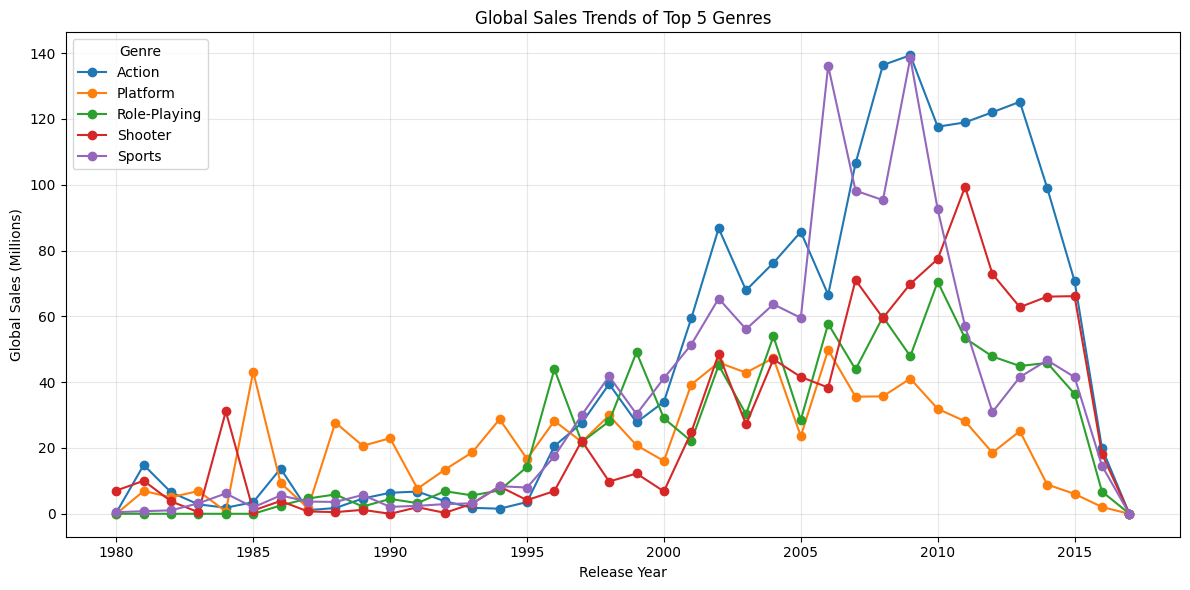

In [34]:
plt.figure(figsize=(12, 6))

for genre in genre_yearly_sales.columns:
    plt.plot(
        genre_yearly_sales.index,
        genre_yearly_sales[genre],
        marker="o",
        label=genre
    )

plt.title("Global Sales Trends of Top 5 Genres")
plt.xlabel("Release Year")
plt.ylabel("Global Sales (Millions)")
plt.legend(title="Genre")
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

Genre Sales Trends Over Time

Action games became one of the strongest-performing genres during the 2000s. Sports games experienced major sales peaks, particularly in 2006 and 2009, while Shooter games reached their highest recorded sales around 2011.

Role-Playing games also showed strong performance during the late 2000s. In contrast, Platform games generally experienced declining sales after the mid-2000s.

The final years should be interpreted cautiously because the dataset may have incomplete sales records.

In [35]:
regional_average = (
    df_clean[
        ["NA_Sales", "EU_Sales", "JP_Sales", "Other_Sales"]
    ].mean()
    .sort_values(ascending=False)
)

print(regional_average.round(4))

NA_Sales       0.2647
EU_Sales       0.1467
JP_Sales       0.0778
Other_Sales    0.0481
dtype: float64


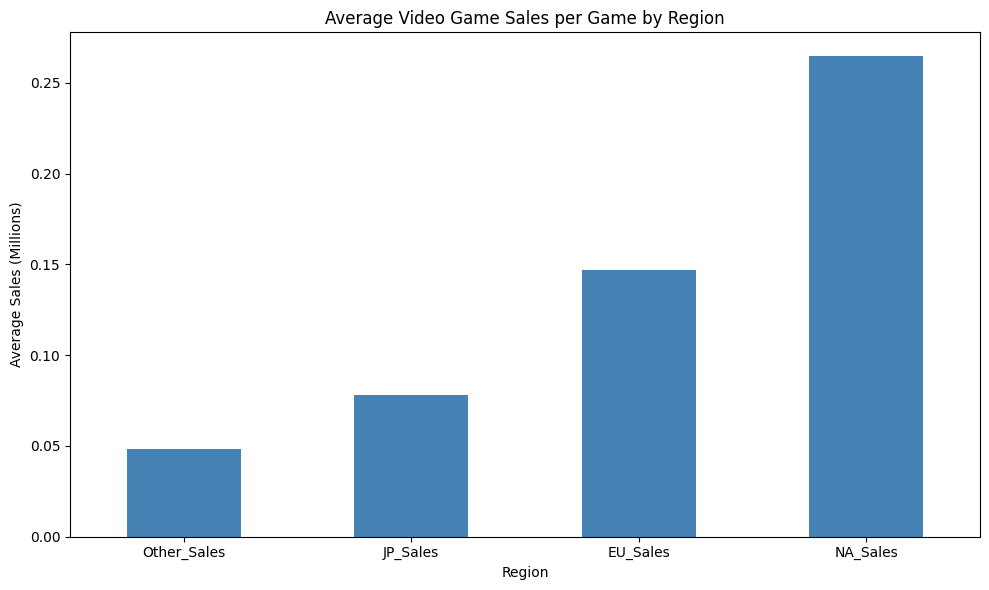

In [36]:
plt.figure(figsize=(10, 6))

regional_average.sort_values().plot(
    kind="bar",
    color="steelblue"
)

plt.title("Average Video Game Sales per Game by Region")
plt.xlabel("Region")
plt.ylabel("Average Sales (Millions)")
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

Average Sales per Game by Region

North America has the highest average sales per game, followed by Europe, Japan, and other regions. This indicates that games in the dataset generally generated more sales in North America and Europe than in Japan and other markets.

In [37]:
platform_summary = (
    df_clean.groupby("Platform")["Global_Sales"]
    .agg(["count", "mean", "sum"])
)

platform_summary.columns = [
    "Game_Count",
    "Average_Sales",
    "Total_Sales"
]

# Focus on platforms with at least 100 games
platform_summary = (
    platform_summary[platform_summary["Game_Count"] >= 100]
    .sort_values("Average_Sales", ascending=False)
)

print(platform_summary.round(2))

          Game_Count  Average_Sales  Total_Sales
Platform                                        
SNES             239           0.84       200.05
PS4              336           0.83       278.10
X360            1265           0.77       979.96
2600             133           0.73        97.08
PS3             1329           0.72       957.84
Wii             1325           0.70       926.71
N64              319           0.69       218.88
XOne             213           0.66       141.06
PS              1196           0.61       730.66
PS2             2161           0.58      1255.64
WiiU             143           0.57        81.86
3DS              509           0.49       247.46
GBA              822           0.39       318.50
DS              2163           0.38       822.49
GC               556           0.36       199.36
XB               824           0.31       258.26
PC               960           0.27       258.82
PSP             1213           0.24       296.28
SAT              173

Platform Performance Analysis

SNES had the highest average global sales per game, followed closely by PS4. However, PS2 generated the highest total global sales, supported by its large game catalog. This demonstrates that a platform's average sales per game and its total sales can produce different rankings.

 INSIGHTS:
1. The highest-performing genre was Plateform.
2. The platform with the highest total sales was PS2.
3. The publisher with the highest total sales was Ninetado.
4. The best-selling game was Wii Sports.
5. The strongest sales region was North America.
6. Sales increased during 1995 to 2010 decreased 2010 to 2020.